# Linear regression with statsmodels

In the previous notebooks we fitted the line by hand. Here we use `statsmodels`, which gives the estimators, the tests on the residuals, the intervals and the influence measures.

Documentation: https://www.statsmodels.org/stable/stats.html

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.stats.stattools as sms
from scipy.stats import normaltest, norm
from statsmodels.stats.outliers_influence import OLSInfluence

In [2]:
dat = np.array([
    [100, 89, 89, 92, 78, 101, 90, 82, 95, 108, 111, 112, 125, 123, 100, 102, 112, 112, 100, 107, 103, 129, 118, 149],
    [709, 740, 586, 806, 694, 760, 664, 509, 619, 652, 772, 896, 742, 831, 667, 772, 838, 679, 889, 690, 698, 860, 799, 882]]).T

dat = dat/10

x = dat[:,0]
Y = dat[:,1]
n = len(dat)

In [3]:
X = sm.add_constant(x)
p = X.shape[1]
results = sm.OLS(Y, X).fit()
print(results.summary())

                            OLS Regression Results                            
Dep. Variable:                      y   R-squared:                       0.382
Model:                            OLS   Adj. R-squared:                  0.354
Method:                 Least Squares   F-statistic:                     13.61
Date:                Mon, 12 Oct 2026   Prob (F-statistic):            0.00128
Time:                        15:47:34   Log-Likelihood:                -83.074
No. Observations:                  24   AIC:                             170.1
Df Residuals:                      22   BIC:                             172.5
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         33.4819     11.098      3.017      0.0

## Tests on the residuals

The summary reports three tests, which can also be computed one by one.

### The Jarque-Bera test

It tests the null hypothesis that the data are normally distributed, against the alternative that they follow some other distribution. The statistic is based on the sample skewness $S$ and the sample kurtosis $K$,
$$JB = n\left(\frac{S^2}{6} + \frac{(K-3)^2}{24}\right),$$
and has an asymptotic $\chi^2_2$ distribution.

In [4]:
name = ['Jarque-Bera', 'Chi^2 two-tail prob.', 'Skew', 'Kurtosis']
test = sms.jarque_bera(results.resid)
pd.Series(test, index=name)

Jarque-Bera             0.653978
Chi^2 two-tail prob.    0.721092
Skew                    0.295823
Kurtosis                2.448698
dtype: float64

### The Omnibus test

It also tests the null hypothesis that the sample comes from a normal distribution. It is the test of D'Agostino and Pearson, which combines skewness and kurtosis.

In [5]:
name = ['Omnibus', 'Chi^2 two-tail prob.']
test = normaltest(results.resid)
pd.Series(test, index=name)

Omnibus                 0.575023
Chi^2 two-tail prob.    0.750128
dtype: float64

### The Durbin-Watson test

The null hypothesis is that there is no serial correlation in the residuals. The statistic is
$$DW = \frac{\sum_{i=2}^n (e_i-e_{i-1})^2}{\sum_{i=1}^n e_i^2} \approx 2(1-r),$$
where $r$ is the sample autocorrelation of the residuals. It is always between 0 and 4: a value of 2 indicates no serial correlation, the closer to 0 the more evidence of positive serial correlation, and the closer to 4 the more evidence of negative serial correlation.

In [6]:
print('Durbin-Watson:', sms.durbin_watson(results.resid))

Durbin-Watson: 2.3815343992342743


## Confidence intervals for the parameters

In [7]:
alpha = 0.05
results.conf_int(alpha=alpha)

array([[10.46534833, 56.49843696],
       [ 1.68393074,  6.00767652]])

## Confidence and prediction intervals

`get_prediction` gives both intervals for any new values of the covariate.

In [8]:
x_grid = np.linspace(7, 15, 50)
X_grid = sm.add_constant(x_grid)

prediction = results.get_prediction(X_grid).summary_frame(alpha=alpha)
prediction.head()

,mean,mean_se,mean_ci_lower,mean_ci_upper,obs_ci_lower,obs_ci_upper
0,60.402518,4.029410,52.046033,68.759003,41.728787,79.076249
1,61.030404,3.874643,52.994887,69.065922,42.498083,79.562726
2,61.658291,3.721223,53.940946,69.375635,43.261693,80.054888
3,62.286177,3.569324,54.883851,69.688503,44.019491,80.552863
4,62.914063,3.419150,55.823181,70.004945,44.771351,81.056775


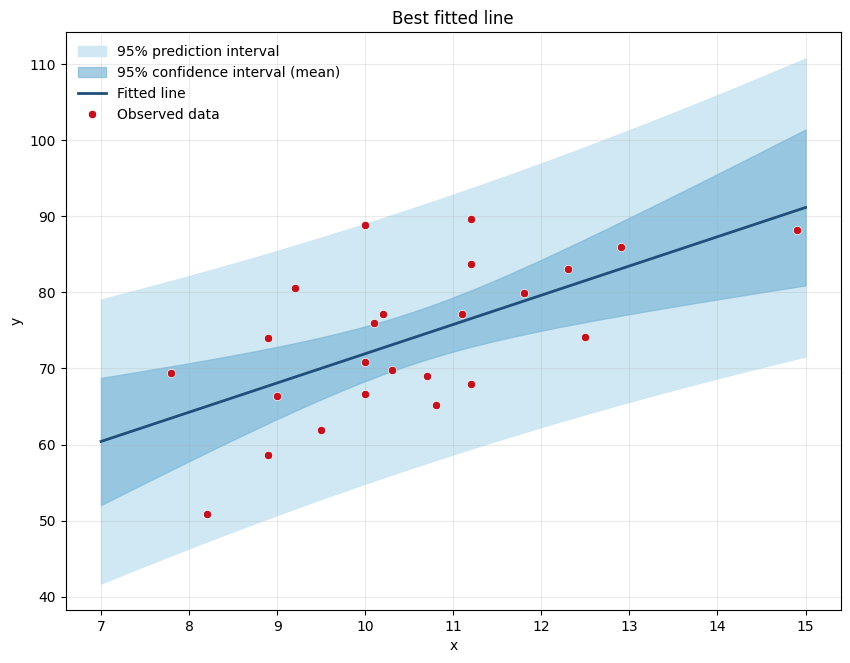

In [9]:
plt.figure(figsize=(10,7.5))

ci_label = f'{(1 - alpha) * 100:.0f}% confidence interval (mean)'
pi_label = f'{(1 - alpha) * 100:.0f}% prediction interval'
plt.fill_between(x_grid, prediction['obs_ci_lower'], prediction['obs_ci_upper'], color='#cfe8f3', label=pi_label)
plt.fill_between(x_grid, prediction['mean_ci_lower'], prediction['mean_ci_upper'], color='#7fb8d8', alpha=0.7, label=ci_label)
plt.plot(x_grid, prediction['mean'], color='#1f4e79', lw=2, label='Fitted line')
plt.plot(x, Y, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5, label='Observed data')

plt.xlabel('x')
plt.ylabel('y')
plt.title('Best fitted line')
plt.legend(loc='best', frameon=False)
plt.grid(True, alpha=0.25)

## Influence of the observations

`OLSInfluence` computes, for each observation, the leverage (`hat_diag`), the studentized residuals, Cook's distance and how much the coefficients change when the observation is left out (`dfb`, `dffits`).

In [10]:
influence = OLSInfluence(results)
frame = influence.summary_frame()
frame.index = np.arange(1, n+1)
frame.round(3)

,dfb_const,dfb_x1,cooks_d,standard_resid,hat_diag,dffits_internal,student_resid,dffits
1,-0.013,0.009,0.000,-0.132,0.046,-0.029,-0.129,-0.028
2,0.203,-0.179,0.031,0.817,0.086,0.251,0.811,0.249
3,-0.298,0.264,0.066,-1.183,0.086,-0.363,-1.195,-0.367
4,0.325,-0.279,0.088,1.512,0.071,0.419,1.561,0.432
5,0.332,-0.309,0.065,0.805,0.166,0.360,0.799,0.357
6,0.040,-0.026,0.005,0.467,0.045,0.101,0.459,0.099
7,-0.051,0.044,0.002,-0.219,0.081,-0.065,-0.215,-0.064
8,-0.708,0.650,0.271,-1.882,0.133,-0.736,-2.008,-0.785
9,-0.174,0.143,0.034,-1.039,0.059,-0.261,-1.041,-0.262
10,0.006,-0.045,0.035,-1.246,0.043,-0.264,-1.263,-0.267


### Residuals

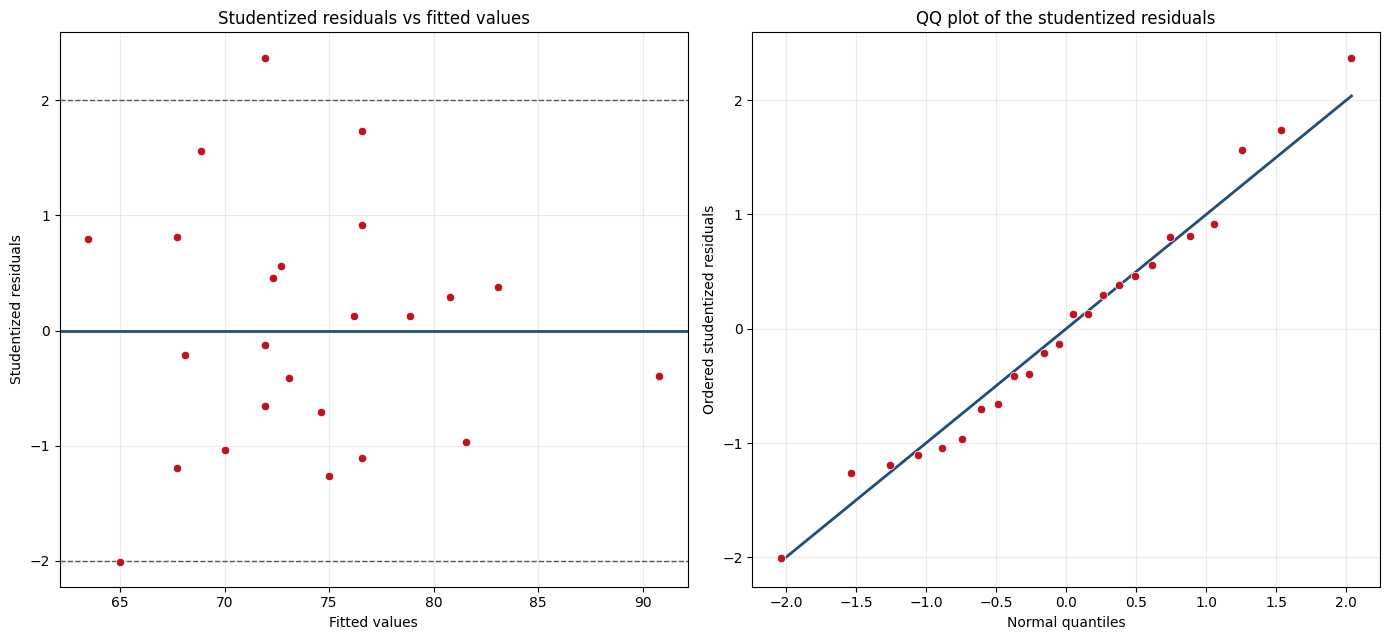

In [11]:
student_resid = frame['student_resid'].to_numpy()
fitted = results.fittedvalues

fig, axes = plt.subplots(1, 2, figsize=(14, 6.5))

axes[0].axhline(0, color='#1f4e79', lw=2)
axes[0].axhline(-2, ls='--', color='#555555', lw=1)
axes[0].axhline(2, ls='--', color='#555555', lw=1)
axes[0].plot(fitted, student_resid, 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5)
axes[0].set_xlabel('Fitted values')
axes[0].set_ylabel('Studentized residuals')
axes[0].set_title('Studentized residuals vs fitted values')

q_theo = norm.ppf((np.arange(1, n+1)-0.5)/n)
axes[1].plot(q_theo, q_theo, color='#1f4e79', lw=2)
axes[1].plot(q_theo, np.sort(student_resid), 'o', color='#c1121f', markersize=6, markeredgecolor='white', markeredgewidth=0.5)
axes[1].set_xlabel('Normal quantiles')
axes[1].set_ylabel('Ordered studentized residuals')
axes[1].set_title('QQ plot of the studentized residuals')

for ax in axes:
    ax.grid(True, alpha=0.25)
plt.tight_layout()

### Leverage against residuals

An observation changes the fit when it has both a high leverage and a large residual. The size of the points is Cook's distance, which combines both.

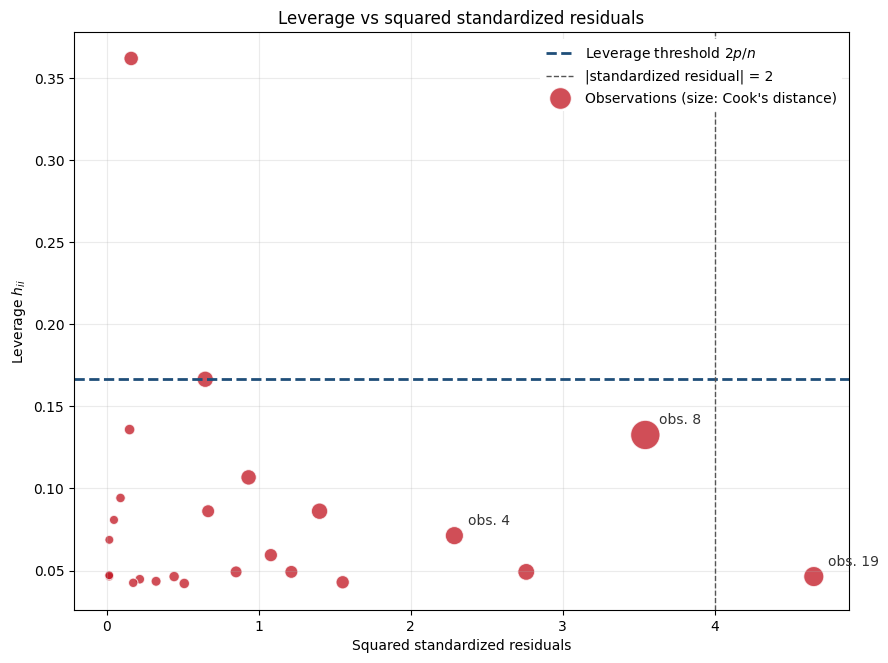

In [12]:
h_ii = frame['hat_diag'].to_numpy()
cooks_d = frame['cooks_d'].to_numpy()
norm_resid_2 = frame['standard_resid'].to_numpy()**2

plt.figure(figsize=(10,7.5))
plt.axhline(2*p/n, ls='--', color='#1f4e79', lw=2, label='Leverage threshold $2p/n$')
plt.axvline(4, ls='--', color='#555555', lw=1, label='|standardized residual| = 2')
plt.scatter(norm_resid_2, h_ii, s=40 + 1500*cooks_d, color='#c1121f', alpha=0.75, edgecolor='white', linewidth=0.8,
            label="Observations (size: Cook's distance)")

# Label the three observations with the largest Cook's distance
for i in np.argsort(-cooks_d)[:3]:
    plt.annotate(f'obs. {i+1}', (norm_resid_2[i], h_ii[i]), xytext=(10, 8), textcoords='offset points',
                 fontsize=10, color='#333333')

plt.xlabel('Squared standardized residuals')
plt.ylabel('Leverage $h_{ii}$')
plt.title('Leverage vs squared standardized residuals')
plt.legend(loc='upper right', framealpha=1, edgecolor='none')
plt.grid(True, alpha=0.25)

The by-hand computation of the intervals and of the confidence region for $\beta$ is in the notebooks `01_best_fit_line` and `05_best_fit_line_conf_region_params`.